# 02 – Single-model daily MSW forecasting

## 1. Setup

In [1]:
%pip install lightgbm prophet statsforecast

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Dell User\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import logging
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from statsforecast.models import AutoARIMA
from prophet import Prophet

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

Importing plotly failed. Interactive plots will not work.


In [4]:
# ---------------- Configuration ----------------
DATA_DIR = "../processed_datasets/outputs"         
DATASETS = {
    "Moratuwa":      "daily_waste_output_Moratuwa_datefixed.csv",
    "Dehiwala":      "daily_waste_output_Dehiwala_datefixed.csv",
    "Boralasgamuwa": "daily_waste_output_Boralasgamuwa_datefixed.csv",
    "Ballarat":      "daily_waste_output_Ballarat_datefixed.csv",
    "Austin":        "daily_waste_output_Austin_datefixed.csv",
}

TEST_RATIO = 0.30            # last 30 % of days = test
N_VAL_FOLDS = 3              # expanding-window CV folds inside the training period
VAL_FRACTION = 0.10          # each validation block = 10 % of the training days
FORECAST_HORIZON = 1         # one-step-ahead (next day)
PRIMARY_METRIC = "RMSE"
WEEKLY_PERIOD = 7

OUTPUT_DIR = "results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Data loading and split

In [5]:
def load_dataset(name, file_name):
    """Load one preprocessed dataset as a continuous daily series.

    Returns a DataFrame indexed by date with:
      y       – daily waste (kg), no gaps
      scored  – True on real recorded days (not imputed, not a filled closure zero)
    """
    path = os.path.join(DATA_DIR, file_name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found – run pre_files/{name.lower()}.ipynb first")

    df = pd.read_csv(path)
    df["ticket_date"] = pd.to_datetime(df["ticket_date"], utc=True).dt.tz_localize(None).dt.normalize()
    df = df.sort_values("ticket_date").set_index("ticket_date")

    if df.index.duplicated().any():
        raise ValueError(f"{name}: duplicate dates in {file_name}")
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    if len(full) != len(df):
        raise ValueError(f"{name}: series is not continuous ({len(full) - len(df)} calendar days missing)")
    if df["net_weight_kg"].isna().any():
        raise ValueError(f"{name}: net_weight_kg still has blanks – preprocessing incomplete")

    out = pd.DataFrame(index=full)
    out["y"] = df["net_weight_kg"].astype(float)
    not_real = pd.Series(False, index=full)
    for flag in ["is_imputed", "is_closure_zero"]:
        if flag in df.columns:
            not_real |= df[flag].astype(bool)
    out["scored"] = ~not_real
    return out


def time_split_index(n_days, test_ratio=TEST_RATIO):
    """Position of the first test day (chronological split, no shuffling)."""
    return int(round(n_days * (1 - test_ratio)))


def validation_folds(n_train, n_folds=N_VAL_FOLDS, val_fraction=VAL_FRACTION):
    """Expanding-window folds inside the training period: (val_start, val_end) positions.
    Each fold trains on everything before val_start and validates on [val_start, val_end)."""
    size = int(n_train * val_fraction)
    return [(n_train - k * size, n_train - (k - 1) * size) for k in range(n_folds, 0, -1)]

In [6]:
data = {}
for name, file_name in DATASETS.items():
    try:
        data[name] = load_dataset(name, file_name)
    except Exception as e:
        print(f"[FAILED] dataset={name} step=data loading: {type(e).__name__}: {e}")

summary = []
for name, d in data.items():
    n_train = time_split_index(len(d))
    summary.append({"dataset": name, "start": d.index[0].date(), "end": d.index[-1].date(), "days": len(d),
                    "train_days": n_train, "test_days": len(d) - n_train,
                    "test_start": d.index[n_train].date(),
                    "scored_test_days": int(d["scored"].iloc[n_train:].sum()),
                    "zero_actuals_in_scored_test": int((d["y"].iloc[n_train:][d["scored"].iloc[n_train:]] == 0).sum())})
if not summary:
    raise RuntimeError(f"No dataset could be loaded from {DATA_DIR} – run the pre_files notebooks first")
pd.DataFrame(summary).set_index("dataset")

,start,end,days,train_days,test_days,test_start,scored_test_days,zero_actuals_in_scored_test
dataset,,,,,,,,
Moratuwa,2015-01-01,2018-12-31,1461,1023,438,2017-10-20,438,0
Dehiwala,2012-01-01,2015-12-31,1461,1023,438,2014-10-20,438,0
Boralasgamuwa,2012-01-01,2018-12-31,2557,1790,767,2016-11-25,767,2
Ballarat,2001-01-01,2011-12-31,4017,2812,1205,2008-09-13,1205,345
Austin,2005-01-01,2011-12-31,2556,1789,767,2009-11-25,767,119


## 3. Metrics

In [7]:
def compute_metrics(actual, predicted):
    """MAE, RMSE and MAPE. Zero actual values are excluded from MAPE only (reported separately)."""
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    err = a - p
    nonzero = a != 0
    return {
        "MAE": float(np.mean(np.abs(err))),
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "MAPE_%": float(np.mean(np.abs(err[nonzero] / a[nonzero])) * 100) if nonzero.any() else np.nan,
        "n_scored": int(len(a)),
        "n_zero_excluded_from_MAPE": int((~nonzero).sum()),
    }


def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual, float) - np.asarray(predicted, float)) ** 2)))

## 4. Lag features

In [8]:
def make_lag_features(y, n_lags):
    """Lag matrix from past values only: column lag_k holds y shifted forward by k days."""
    return pd.concat({f"lag_{k}": y.shift(k) for k in range(1, n_lags + 1)}, axis=1)

## 5. Model functions

In [9]:
def tune_and_fit_lag_model(build_model, grid, y, scored, n_train):
    """Shared routine for the three lag-feature regressors.

    build_model(params) -> unfitted model. Each params dict contains 'lags' plus model settings.
    1. choose params by expanding-window CV inside the training period (RMSE on real days)
    2. refit on all real training days with the chosen params
    3. predict every test day from its lags (one-step-ahead)
    """
    positions = np.arange(len(y))
    cv_rows = []
    for params in grid:
        X = make_lag_features(y, params["lags"])
        usable = X.notna().all(axis=1).to_numpy() & scored.to_numpy()
        fold_errors = []
        for val_start, val_end in validation_folds(n_train):
            tr = usable & (positions < val_start)
            va = usable & (positions >= val_start) & (positions < val_end)
            model = build_model(params)
            model.fit(X[tr], y[tr])
            fold_errors.append(rmse(y[va], model.predict(X[va])))
        cv_rows.append({**params, "cv_rmse": float(np.mean(fold_errors))})

    cv_table = pd.DataFrame(cv_rows).sort_values("cv_rmse").reset_index(drop=True)
    best = {k: v for k, v in cv_table.iloc[0].to_dict().items() if k != "cv_rmse"}
    best = {k: (int(v) if isinstance(v, float) and float(v).is_integer() else v) for k, v in best.items()}

    X = make_lag_features(y, best["lags"])
    usable = X.notna().all(axis=1).to_numpy() & scored.to_numpy()
    train_rows = usable & (positions < n_train)
    model = build_model(best)
    model.fit(X[train_rows], y[train_rows])
    test_X = X.iloc[n_train:]
    pred = pd.Series(model.predict(test_X), index=test_X.index)
    return pred, best, cv_table

In [10]:
def run_linear_regression(y, scored, n_train):
    """Multiple linear regression on lag features. Tuned: number of lags."""
    grid = [{"lags": l} for l in [7, 14, 28]]
    return tune_and_fit_lag_model(lambda p: LinearRegression(), grid, y, scored, n_train)


def run_random_forest(y, scored, n_train):
    """Random forest on lag features. Tuned: lags, max_depth, min_samples_leaf."""
    grid = [{"lags": l, "max_depth": d, "min_samples_leaf": m}
            for l in [7, 14, 28] for d in [8, 16] for m in [1, 5]]
    build = lambda p: RandomForestRegressor(n_estimators=300, max_depth=int(p["max_depth"]),
                                            min_samples_leaf=int(p["min_samples_leaf"]),
                                            random_state=SEED, n_jobs=-1)
    return tune_and_fit_lag_model(build, grid, y, scored, n_train)


def run_lightgbm(y, scored, n_train):
    """LightGBM on lag features. Tuned: lags, num_leaves, learning_rate."""
    grid = [{"lags": l, "num_leaves": nl, "learning_rate": lr}
            for l in [7, 14, 28] for nl in [15, 31] for lr in [0.03, 0.1]]
    build = lambda p: lgb.LGBMRegressor(n_estimators=400, num_leaves=int(p["num_leaves"]),
                                        learning_rate=float(p["learning_rate"]), subsample=0.8,
                                        subsample_freq=1, colsample_bytree=0.8,
                                        random_state=SEED, deterministic=True, verbose=-1)
    return tune_and_fit_lag_model(build, grid, y, scored, n_train)

In [11]:
def run_auto_arima(y, scored, n_train):
    """Auto ARIMA (statsforecast) with weekly seasonality.

    Orders and coefficients are selected on the training period only (stepwise search, AICc).
    The fitted model is then run through the whole series without re-estimation: the in-sample
    'fitted' values of a state-space ARIMA are one-step-ahead predictions, so the values for the
    test days use only observations up to the previous day.
    ARIMA needs a gap-free series, so it is fitted on the full preprocessed training series.
    """
    model = AutoARIMA(season_length=WEEKLY_PERIOD)
    model.fit(y.iloc[:n_train].to_numpy(dtype=float))
    out = model.forward(y=y.to_numpy(dtype=float), h=FORECAST_HORIZON, fitted=True)
    fitted = np.asarray(out["fitted"], dtype=float)
    pred = pd.Series(fitted[n_train:], index=y.index[n_train:])

    try:
        from statsforecast.arima import arima_string
        order = arima_string(model.model_)
    except Exception:
        order = "see model.model_"
    cv_table = pd.DataFrame([{"selection": "AICc on training data", "model": order}])
    return pred, {"model": order}, cv_table


def run_prophet(y, scored, n_train):
    """Prophet with weekly and yearly seasonality.

    Prophet needs columns 'ds' (date) and 'y' (target). Days that are not real recorded values
    are set to NaN, and Prophet skips them when fitting.
    Tuned on training-period folds: changepoint_prior_scale and seasonality_mode.
    Prophet has no lagged inputs, so its forecast for a date does not use recent observations.
    """
    frame = pd.DataFrame({"ds": y.index, "y": y.where(scored).to_numpy()})

    def fit_predict(train_frame, future_dates, params):
        m = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False,
                    changepoint_prior_scale=params["changepoint_prior_scale"],
                    seasonality_mode=params["seasonality_mode"])
        m.fit(train_frame)
        return m.predict(pd.DataFrame({"ds": future_dates}))["yhat"].to_numpy()

    grid = [{"changepoint_prior_scale": c, "seasonality_mode": s}
            for c in [0.01, 0.1, 0.5] for s in ["additive", "multiplicative"]]
    cv_rows = []
    for params in grid:
        fold_errors = []
        for val_start, val_end in validation_folds(n_train):
            pred = fit_predict(frame.iloc[:val_start], frame["ds"].iloc[val_start:val_end], params)
            mask = scored.iloc[val_start:val_end].to_numpy()
            fold_errors.append(rmse(y.iloc[val_start:val_end][mask], pred[mask]))
        cv_rows.append({**params, "cv_rmse": float(np.mean(fold_errors))})
    cv_table = pd.DataFrame(cv_rows).sort_values("cv_rmse").reset_index(drop=True)
    best = {k: v for k, v in cv_table.iloc[0].to_dict().items() if k != "cv_rmse"}

    pred = fit_predict(frame.iloc[:n_train], frame["ds"].iloc[n_train:], best)
    return pd.Series(pred, index=y.index[n_train:]), best, cv_table


def run_seasonal_naive(y, scored, n_train):
    """Reference only (not ranked): forecast = value on the same weekday one week earlier."""
    pred = y.shift(WEEKLY_PERIOD).iloc[n_train:]
    return pred, {"rule": "y[t-7]"}, pd.DataFrame()


MODELS = {
    "Multiple Linear Regression": run_linear_regression,
    "Auto ARIMA": run_auto_arima,
    "LightGBM": run_lightgbm,
    "Random Forest": run_random_forest,
    "Prophet": run_prophet,
}
REFERENCE = {"Seasonal naive (reference)": run_seasonal_naive}

## 6. Train, forecast and evaluate every dataset × model

In [12]:
def safe_name(text):
    return "".join(c if c.isalnum() else "_" for c in text).strip("_")


def plot_prediction(dataset, model_name, result, path):
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(result.index, result["actual"].where(result["scored"]), lw=1, color="black", label="actual (real days)")
    ax.plot(result.index, result["predicted"], lw=1, color="tab:orange", alpha=0.85, label="predicted")
    ax.set_title(f"{dataset} – {model_name}: one-step-ahead forecast on the test period")
    ax.set_ylabel("kg"); ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(path, dpi=120); plt.close(fig)


metrics_rows, errors, selected_params, all_predictions = [], [], {}, {}

for dataset, d in data.items():
    out_dir = os.path.join(OUTPUT_DIR, safe_name(dataset))
    os.makedirs(out_dir, exist_ok=True)
    n_train = time_split_index(len(d))
    y, scored = d["y"], d["scored"]
    test_index = d.index[n_train:]

    for model_name, run in {**MODELS, **REFERENCE}.items():
        print(f"Running dataset={dataset} model={model_name} ...", flush=True)
        try:
            pred, params, cv_table = run(y, scored, n_train)
            pred = pred.reindex(test_index).clip(lower=0)
            if pred.isna().any():
                raise ValueError(f"{int(pred.isna().sum())} test days have no prediction")

            result = pd.DataFrame({"actual": y.iloc[n_train:], "predicted": pred, "scored": scored.iloc[n_train:]})
            result.index.name = "date"
            m = compute_metrics(result.loc[result["scored"], "actual"], result.loc[result["scored"], "predicted"])
            metrics_rows.append({"dataset": dataset, "model": model_name, **m})
            selected_params[(dataset, model_name)] = params
            all_predictions[(dataset, model_name)] = result

            tag = safe_name(model_name)
            result.to_csv(os.path.join(out_dir, f"predictions_{tag}.csv"))
            if len(cv_table):
                cv_table.to_csv(os.path.join(out_dir, f"validation_{tag}.csv"), index=False)
            plot_prediction(dataset, model_name, result, os.path.join(out_dir, f"plot_{tag}.png"))
            print(f"   done: RMSE {m['RMSE']:,.0f} | MAE {m['MAE']:,.0f} | MAPE {m['MAPE_%']:.2f} % | params {params}")
        except Exception as e:
            errors.append({"dataset": dataset, "model": model_name, "error": f"{type(e).__name__}: {e}",
                           "traceback": traceback.format_exc()})
            print(f"[FAILED] dataset={dataset} model={model_name}: {type(e).__name__}: {e}")

print(f"\nFinished: {len(metrics_rows)} successful runs, {len(errors)} failures")
if errors:
    display(pd.DataFrame(errors)[["dataset", "model", "error"]])
    pd.DataFrame(errors).to_csv(os.path.join(OUTPUT_DIR, "errors.csv"), index=False)

Running dataset=Moratuwa model=Multiple Linear Regression ...
   done: RMSE 18,589 | MAE 13,672 | MAPE 19.87 % | params {'lags': 28}
Running dataset=Moratuwa model=Auto ARIMA ...
   done: RMSE 18,602 | MAE 13,506 | MAPE 20.31 % | params {'model': 'ARIMA(0,1,2)(1,0,1)[7]                   '}
Running dataset=Moratuwa model=LightGBM ...
   done: RMSE 19,501 | MAE 14,172 | MAPE 21.35 % | params {'lags': 28, 'num_leaves': 31, 'learning_rate': 0.03}
Running dataset=Moratuwa model=Random Forest ...
   done: RMSE 18,329 | MAE 13,008 | MAPE 19.89 % | params {'lags': 28, 'max_depth': 16, 'min_samples_leaf': 5}
Running dataset=Moratuwa model=Prophet ...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
13:48:16 - cmdstanpy - INFO - Chain [1] start processing
13:48:19 - cmdstanpy - INFO - Chain [1] done processing
13:48:26 - cmdstanpy - INFO - Chain [1] start processing
13:48:29 - cmdstanpy - INFO - Chain [1] done processing
13:48:30 - cmdstanpy - INFO - Chain [1] start processing
13:48:31 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
13:48:32 - cmdstanpy - INFO - Chain [1] start processing
13:48:32 - cmdstanpy - INF

   done: RMSE 28,420 | MAE 21,319 | MAPE 33.73 % | params {'changepoint_prior_scale': 0.5, 'seasonality_mode': 'additive'}
Running dataset=Moratuwa model=Seasonal naive (reference) ...
   done: RMSE 22,391 | MAE 16,418 | MAPE 22.89 % | params {'rule': 'y[t-7]'}
Running dataset=Dehiwala model=Multiple Linear Regression ...
   done: RMSE 29,998 | MAE 20,791 | MAPE 20.11 % | params {'lags': 28}
Running dataset=Dehiwala model=Auto ARIMA ...
   done: RMSE 27,914 | MAE 18,525 | MAPE 19.13 % | params {'model': 'ARIMA(1,0,1)(0,1,2)[7] with drift        '}
Running dataset=Dehiwala model=LightGBM ...
   done: RMSE 29,656 | MAE 20,200 | MAPE 20.21 % | params {'lags': 28, 'num_leaves': 31, 'learning_rate': 0.03}
Running dataset=Dehiwala model=Random Forest ...
   done: RMSE 29,983 | MAE 20,522 | MAPE 20.53 % | params {'lags': 28, 'max_depth': 16, 'min_samples_leaf': 5}
Running dataset=Dehiwala model=Prophet ...


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
13:51:22 - cmdstanpy - INFO - Chain [1] start processing
13:51:24 - cmdstanpy - INFO - Chain [1] done processing
13:51:24 - cmdstanpy - INFO - Chain [1] start processing
13:51:26 - cmdstanpy - INFO - Chain [1] done processing
13:51:26 - cmdstanpy - INFO - Chain [1] start processing
13:51:27 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
13:51:28 - cmdstanpy - INFO - Chain [1] start processing
13:51:29 - cmdstanpy - INF

   done: RMSE 32,293 | MAE 21,366 | MAPE 23.30 % | params {'changepoint_prior_scale': 0.01, 'seasonality_mode': 'additive'}
Running dataset=Dehiwala model=Seasonal naive (reference) ...
   done: RMSE 36,621 | MAE 24,450 | MAPE 22.62 % | params {'rule': 'y[t-7]'}
Running dataset=Boralasgamuwa model=Multiple Linear Regression ...
   done: RMSE 6,439 | MAE 4,829 | MAPE 21.31 % | params {'lags': 28}
Running dataset=Boralasgamuwa model=Auto ARIMA ...
   done: RMSE 6,302 | MAE 4,664 | MAPE 20.42 % | params {'model': 'ARIMA(1,0,4)(2,1,2)[7]                   '}
Running dataset=Boralasgamuwa model=LightGBM ...
   done: RMSE 6,583 | MAE 4,919 | MAPE 22.28 % | params {'lags': 28, 'num_leaves': 31, 'learning_rate': 0.03}
Running dataset=Boralasgamuwa model=Random Forest ...
   done: RMSE 6,356 | MAE 4,684 | MAPE 21.35 % | params {'lags': 28, 'max_depth': 16, 'min_samples_leaf': 5}
Running dataset=Boralasgamuwa model=Prophet ...


...

   done: RMSE 12,411 | MAE 10,681 | MAPE 39.95 % | params {'changepoint_prior_scale': 0.5, 'seasonality_mode': 'additive'}
Running dataset=Boralasgamuwa model=Seasonal naive (reference) ...
   done: RMSE 8,393 | MAE 6,273 | MAPE 26.73 % | params {'rule': 'y[t-7]'}
Running dataset=Ballarat model=Multiple Linear Regression ...
   done: RMSE 7,755 | MAE 4,469 | MAPE 7.44 % | params {'lags': 28}
Running dataset=Ballarat model=Auto ARIMA ...
   done: RMSE 7,421 | MAE 4,245 | MAPE 7.09 % | params {'model': 'ARIMA(5,0,1)(1,1,2)[7]                   '}
Running dataset=Ballarat model=LightGBM ...
   done: RMSE 9,093 | MAE 5,978 | MAPE 7.98 % | params {'lags': 28, 'num_leaves': 31, 'learning_rate': 0.03}
Running dataset=Ballarat model=Random Forest ...
   done: RMSE 8,849 | MAE 5,553 | MAPE 7.12 % | params {'lags': 28, 'max_depth': 16, 'min_samples_leaf': 5}
Running dataset=Ballarat model=Prophet ...


14:03:49 - cmdstanpy - INFO - Chain [1] start processing
14:03:52 - cmdstanpy - INFO - Chain [1] done processing
14:03:55 - cmdstanpy - INFO - Chain [1] start processing
14:03:56 - cmdstanpy - INFO - Chain [1] done processing
14:04:01 - cmdstanpy - INFO - Chain [1] start processing
14:04:03 - cmdstanpy - INFO - Chain [1] done processing
14:04:04 - cmdstanpy - INFO - Chain [1] start processing
14:04:05 - cmdstanpy - INFO - Chain [1] done processing
14:04:06 - cmdstanpy - INFO - Chain [1] start processing
14:04:06 - cmdstanpy - INFO - Chain [1] done processing
14:04:07 - cmdstanpy - INFO - Chain [1] start processing
14:04:08 - cmdstanpy - INFO - Chain [1] done processing
14:04:09 - cmdstanpy - INFO - Chain [1] start processing
14:04:10 - cmdstanpy - INFO - Chain [1] done processing
14:04:11 - cmdstanpy - INFO - Chain [1] start processing
14:04:12 - cmdstanpy - INFO - Chain [1] done processing
14:04:13 - cmdstanpy - INFO - Chain [1] start processing
14:04:14 - cmdstanpy - INFO - Chain [1]

   done: RMSE 10,980 | MAE 7,787 | MAPE 11.31 % | params {'changepoint_prior_scale': 0.01, 'seasonality_mode': 'additive'}
Running dataset=Ballarat model=Seasonal naive (reference) ...
   done: RMSE 8,377 | MAE 4,071 | MAPE 7.20 % | params {'rule': 'y[t-7]'}
Running dataset=Austin model=Multiple Linear Regression ...
   done: RMSE 176,815 | MAE 86,072 | MAPE 131.59 % | params {'lags': 28}
Running dataset=Austin model=Auto ARIMA ...
   done: RMSE 169,096 | MAE 84,216 | MAPE 116.06 % | params {'model': 'ARIMA(2,0,1)(0,1,2)[7]                   '}
Running dataset=Austin model=LightGBM ...
   done: RMSE 162,516 | MAE 82,152 | MAPE 139.30 % | params {'lags': 28, 'num_leaves': 31, 'learning_rate': 0.03}
Running dataset=Austin model=Random Forest ...
   done: RMSE 184,716 | MAE 88,201 | MAPE 78.49 % | params {'lags': 7, 'max_depth': 16, 'min_samples_leaf': 1}
Running dataset=Austin model=Prophet ...


14:08:07 - cmdstanpy - INFO - Chain [1] start processing
14:08:09 - cmdstanpy - INFO - Chain [1] done processing
14:08:13 - cmdstanpy - INFO - Chain [1] start processing
14:08:14 - cmdstanpy - INFO - Chain [1] done processing
14:08:16 - cmdstanpy - INFO - Chain [1] start processing
14:08:16 - cmdstanpy - INFO - Chain [1] done processing
14:08:17 - cmdstanpy - INFO - Chain [1] start processing
14:08:18 - cmdstanpy - INFO - Chain [1] done processing
14:08:18 - cmdstanpy - INFO - Chain [1] start processing
14:08:19 - cmdstanpy - INFO - Chain [1] done processing
14:08:20 - cmdstanpy - INFO - Chain [1] start processing
14:08:20 - cmdstanpy - INFO - Chain [1] done processing
14:08:21 - cmdstanpy - INFO - Chain [1] start processing
14:08:22 - cmdstanpy - INFO - Chain [1] done processing
14:08:25 - cmdstanpy - INFO - Chain [1] start processing
14:08:25 - cmdstanpy - INFO - Chain [1] done processing
14:08:27 - cmdstanpy - INFO - Chain [1] start processing
14:08:28 - cmdstanpy - INFO - Chain [1]

   done: RMSE 188,013 | MAE 117,348 | MAPE 475.84 % | params {'changepoint_prior_scale': 0.01, 'seasonality_mode': 'additive'}
Running dataset=Austin model=Seasonal naive (reference) ...
   done: RMSE 208,466 | MAE 94,261 | MAPE 22.62 % | params {'rule': 'y[t-7]'}

Finished: 30 successful runs, 0 failures


## 7. Metrics for every dataset–model combination

In [13]:
metrics = pd.DataFrame(metrics_rows)
params_col = [str(selected_params.get((r.dataset, r.model), "")) for r in metrics.itertuples()]
metrics["selected_params"] = params_col
metrics.to_csv(os.path.join(OUTPUT_DIR, "metrics_all.csv"), index=False)
metrics.round(2)

,dataset,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE,selected_params
0,Moratuwa,Multiple Linear Regression,13672.09,18589.35,19.87,438,0,{'lags': 28}
1,Moratuwa,Auto ARIMA,13505.54,18602.49,20.31,438,0,"{'model': 'ARIMA(0,1,2)(1,0,1)[7] ..."
2,Moratuwa,LightGBM,14172.08,19500.96,21.35,438,0,"{'lags': 28, 'num_leaves': 31, 'learning_rate'..."
3,Moratuwa,Random Forest,13008.27,18328.83,19.89,438,0,"{'lags': 28, 'max_depth': 16, 'min_samples_lea..."
4,Moratuwa,Prophet,21319.33,28420.13,33.73,438,0,"{'changepoint_prior_scale': 0.5, 'seasonality_..."
5,Moratuwa,Seasonal naive (reference),16417.59,22390.61,22.89,438,0,{'rule': 'y[t-7]'}
6,Dehiwala,Multiple Linear Regression,20791.28,29997.94,20.11,438,0,{'lags': 28}
7,Dehiwala,Auto ARIMA,18524.79,27914.12,19.13,438,0,"{'model': 'ARIMA(1,0,1)(0,1,2)[7] with drift ..."
8,Dehiwala,LightGBM,20199.77,29656.10,20.21,438,0,"{'lags': 28, 'num_leaves': 31, 'learning_rate'..."
9,Dehiwala,Random Forest,20522.43,29982.84,20.53,438,0,"{'lags': 28, 'max_depth': 16, 'min_samples_lea..."


## 8. Model comparison and ranking

Models are ranked **within each dataset** by the primary metric. RMSE is in kg, and the datasets have very different scales, so raw RMSE is not compared across datasets.
The overall ranking uses the **mean rank** across datasets (1 = best). The seasonal-naive reference is shown but not ranked.

In [14]:
ranked = metrics[metrics["model"].isin(MODELS)].copy()
ranked["rank"] = ranked.groupby("dataset")[PRIMARY_METRIC].rank(method="min")

comparison = ranked.pivot(index="model", columns="dataset", values=PRIMARY_METRIC)
comparison.columns = [f"{c} {PRIMARY_METRIC}" for c in comparison.columns]
rank_table = ranked.pivot(index="model", columns="dataset", values="rank")
rank_table.columns = [f"{c} rank" for c in rank_table.columns]
mape_table = ranked.pivot(index="model", columns="dataset", values="MAPE_%")
mape_table.columns = [f"{c} MAPE %" for c in mape_table.columns]

ranking = pd.concat([rank_table, comparison, mape_table], axis=1)
ranking["mean rank"] = rank_table.mean(axis=1)
ranking = ranking.sort_values("mean rank")
ranking.to_csv(os.path.join(OUTPUT_DIR, "model_ranking.csv"))
ranking.round(2)

,Austin rank,Ballarat rank,Boralasgamuwa rank,Dehiwala rank,Moratuwa rank,Austin RMSE,Ballarat RMSE,Boralasgamuwa RMSE,Dehiwala RMSE,Moratuwa RMSE,Austin MAPE %,Ballarat MAPE %,Boralasgamuwa MAPE %,Dehiwala MAPE %,Moratuwa MAPE %,mean rank
model,,,,,,,,,,,,,,,,
Auto ARIMA,2.0,1.0,1.0,1.0,3.0,169095.74,7420.63,6301.99,27914.12,18602.49,116.06,7.09,20.42,19.13,20.31,1.6
Random Forest,4.0,3.0,2.0,3.0,1.0,184715.80,8848.92,6355.84,29982.84,18328.83,78.49,7.12,21.35,20.53,19.89,2.6
Multiple Linear Regression,3.0,2.0,3.0,4.0,2.0,176815.00,7754.75,6439.42,29997.94,18589.35,131.59,7.44,21.31,20.11,19.87,2.8
LightGBM,1.0,4.0,4.0,2.0,4.0,162515.90,9092.84,6582.66,29656.10,19500.96,139.30,7.98,22.28,20.21,21.35,3.0
Prophet,5.0,5.0,5.0,5.0,5.0,188012.51,10979.95,12410.65,32292.68,28420.13,475.84,11.31,39.95,23.30,33.73,5.0


In [15]:
# Per-dataset ranking, with the seasonal-naive reference for context
for dataset, part in metrics.groupby("dataset", sort=False):
    print(f"\n=== {dataset} (ranked by {PRIMARY_METRIC}) ===")
    display(part.sort_values(PRIMARY_METRIC)[["model", "MAE", "RMSE", "MAPE_%", "n_scored",
                                              "n_zero_excluded_from_MAPE"]].round(2).reset_index(drop=True))


=== Moratuwa (ranked by RMSE) ===


,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE
0,Random Forest,13008.27,18328.83,19.89,438,0
1,Multiple Linear Regression,13672.09,18589.35,19.87,438,0
2,Auto ARIMA,13505.54,18602.49,20.31,438,0
3,LightGBM,14172.08,19500.96,21.35,438,0
4,Seasonal naive (reference),16417.59,22390.61,22.89,438,0
5,Prophet,21319.33,28420.13,33.73,438,0



=== Dehiwala (ranked by RMSE) ===


,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE
0,Auto ARIMA,18524.79,27914.12,19.13,438,0
1,LightGBM,20199.77,29656.10,20.21,438,0
2,Random Forest,20522.43,29982.84,20.53,438,0
3,Multiple Linear Regression,20791.28,29997.94,20.11,438,0
4,Prophet,21366.08,32292.68,23.30,438,0
5,Seasonal naive (reference),24449.92,36621.38,22.62,438,0



=== Boralasgamuwa (ranked by RMSE) ===


,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE
0,Auto ARIMA,4663.90,6301.99,20.42,767,2
1,Random Forest,4684.03,6355.84,21.35,767,2
2,Multiple Linear Regression,4828.64,6439.42,21.31,767,2
3,LightGBM,4918.56,6582.66,22.28,767,2
4,Seasonal naive (reference),6273.34,8392.80,26.73,767,2
5,Prophet,10681.15,12410.65,39.95,767,2



=== Ballarat (ranked by RMSE) ===


,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE
0,Auto ARIMA,4244.55,7420.63,7.09,1205,345
1,Multiple Linear Regression,4468.60,7754.75,7.44,1205,345
2,Seasonal naive (reference),4071.22,8376.84,7.20,1205,345
3,Random Forest,5553.35,8848.92,7.12,1205,345
4,LightGBM,5977.55,9092.84,7.98,1205,345
5,Prophet,7786.94,10979.95,11.31,1205,345



=== Austin (ranked by RMSE) ===


,model,MAE,RMSE,MAPE_%,n_scored,n_zero_excluded_from_MAPE
0,LightGBM,82151.59,162515.90,139.30,767,119
1,Auto ARIMA,84215.78,169095.74,116.06,767,119
2,Multiple Linear Regression,86072.14,176815.00,131.59,767,119
3,Random Forest,88200.88,184715.80,78.49,767,119
4,Prophet,117347.95,188012.51,475.84,767,119
5,Seasonal naive (reference),94260.76,208466.15,22.62,767,119


## 9. Forecast plots per dataset (all models)

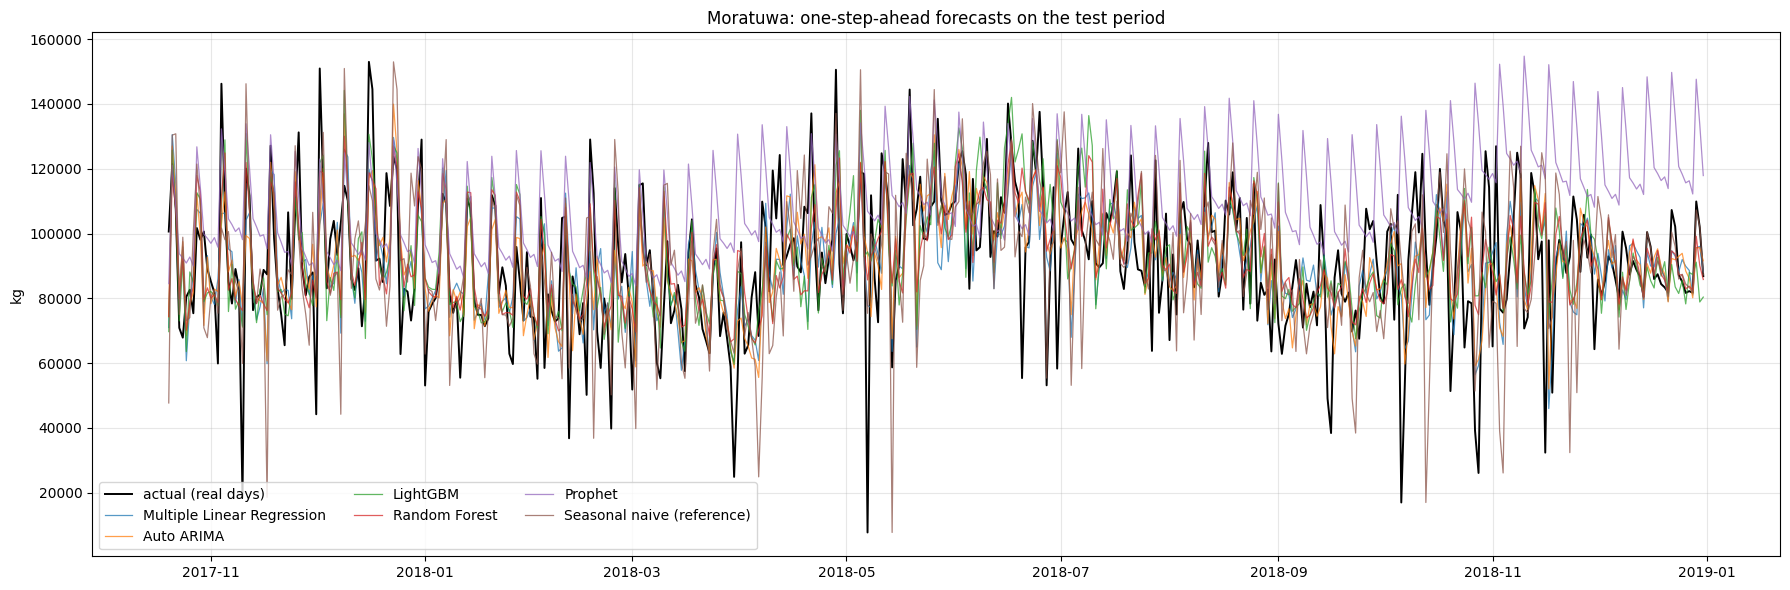

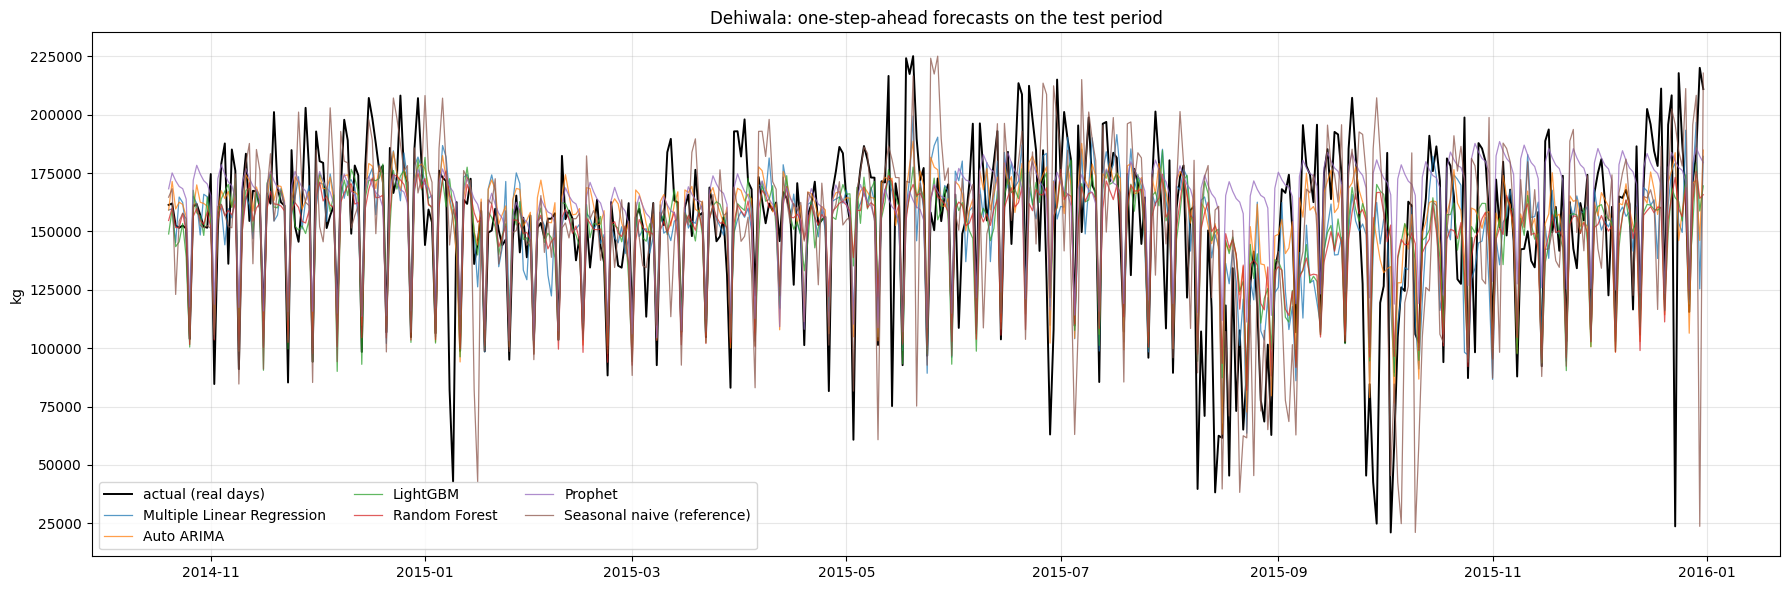

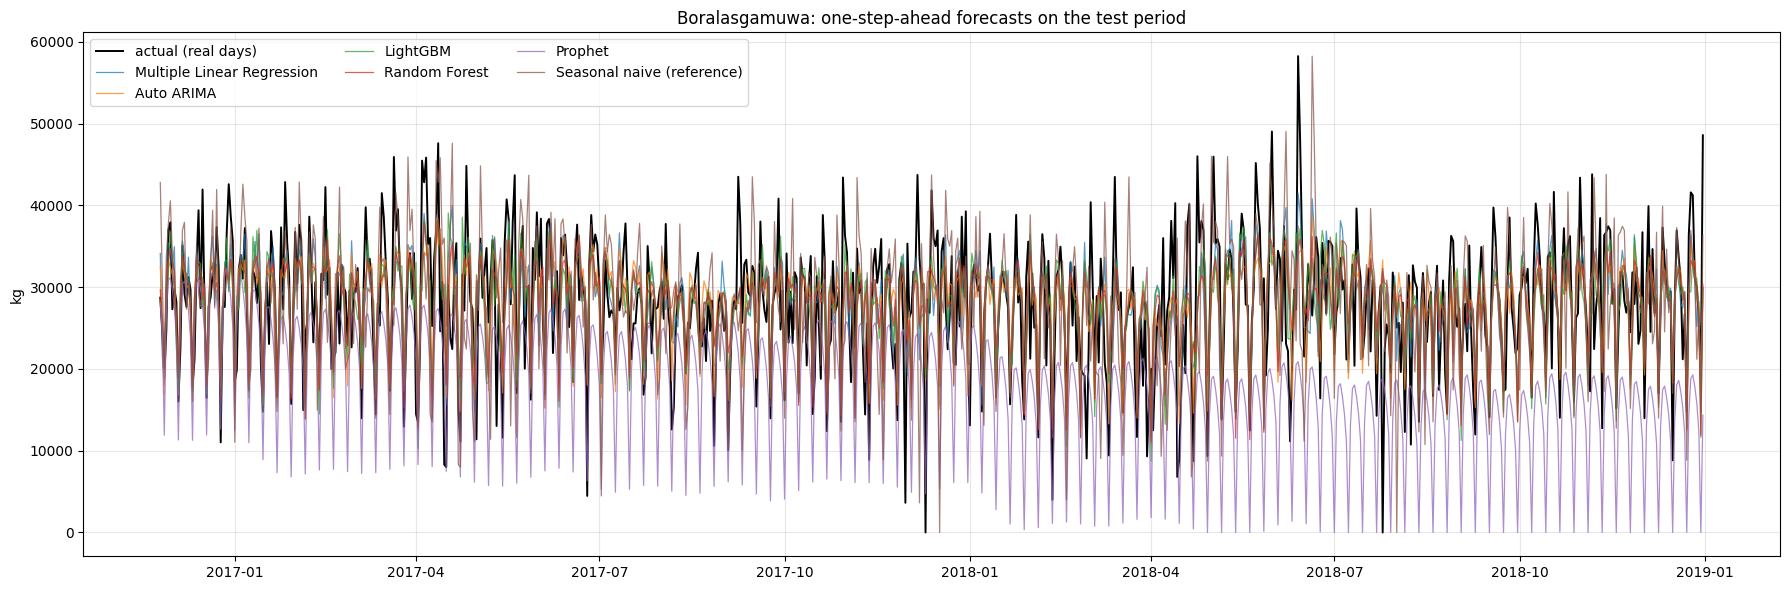

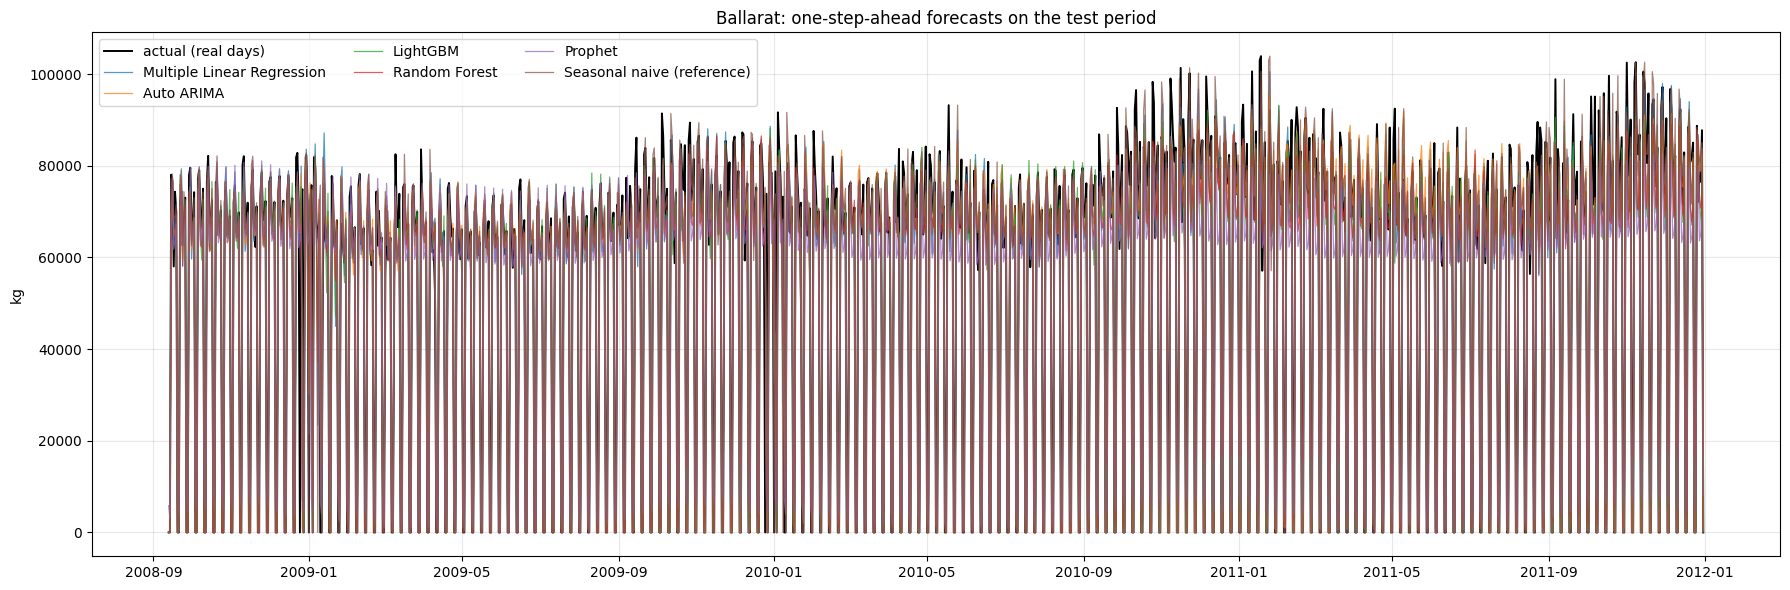

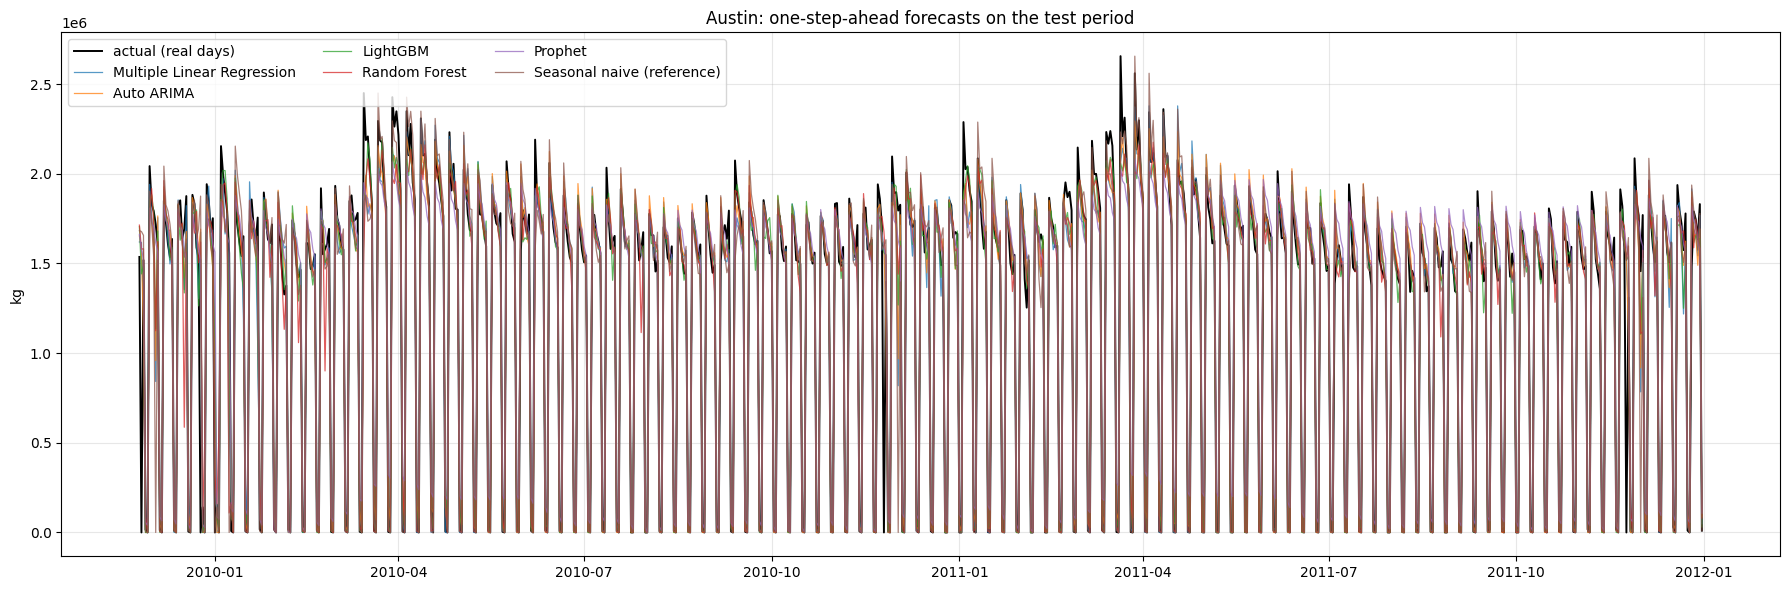

In [16]:
for dataset in data:
    keys = [k for k in all_predictions if k[0] == dataset]
    if not keys:
        continue
    fig, ax = plt.subplots(figsize=(18, 6))
    first = all_predictions[keys[0]]
    ax.plot(first.index, first["actual"].where(first["scored"]), color="black", lw=1.4, label="actual (real days)")
    for _, model_name in keys:
        r = all_predictions[(dataset, model_name)]
        ax.plot(r.index, r["predicted"], lw=0.9, alpha=0.75, label=model_name)
    ax.set_title(f"{dataset}: one-step-ahead forecasts on the test period"); ax.set_ylabel("kg")
    ax.legend(ncol=3); ax.grid(alpha=0.3); fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, safe_name(dataset), "plot_all_models.png"), dpi=120)
    plt.show()

## 10. Saved outputs

| File | Content |
|---|---|
| `results/<dataset>/predictions_<model>.csv` | date, actual, predicted, scored (True = real day used in metrics) |
| `results/<dataset>/validation_<model>.csv` | cross-validation results used to choose hyperparameters (training data only) |
| `results/<dataset>/plot_<model>.png`, `plot_all_models.png` | actual vs predicted on the test period |
| `results/metrics_all.csv` | MAE, RMSE, MAPE, scored days, zero days excluded from MAPE, selected parameters |
| `results/model_ranking.csv` | rank per dataset by the primary metric and mean rank |
| `results/errors.csv` | only if a dataset–model run failed |